📦 Generating a mock COCO dataset for auditing...
✅ Mock dataset created.

🖼️ UPLOAD AN IMAGE FOR LIVE QUALITY AUDIT


Saving shishi.jpeg to shishi (2).jpeg
✅ Image: shishi (2).jpeg
   • Brightness: 89.03 / 255
   • Contrast  : 71.60
   • Verdict   : ✅ Good Quality

🔍 Running Dataset Audit...
  • Total Annotations: 83
  • Valid Boxes      : 67
  • Invalid Boxes    : 16

📊 Generating Audit Graphs...


/tmp/ipykernel_571/1105031510.py:199: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_571/1105031510.py:199: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()


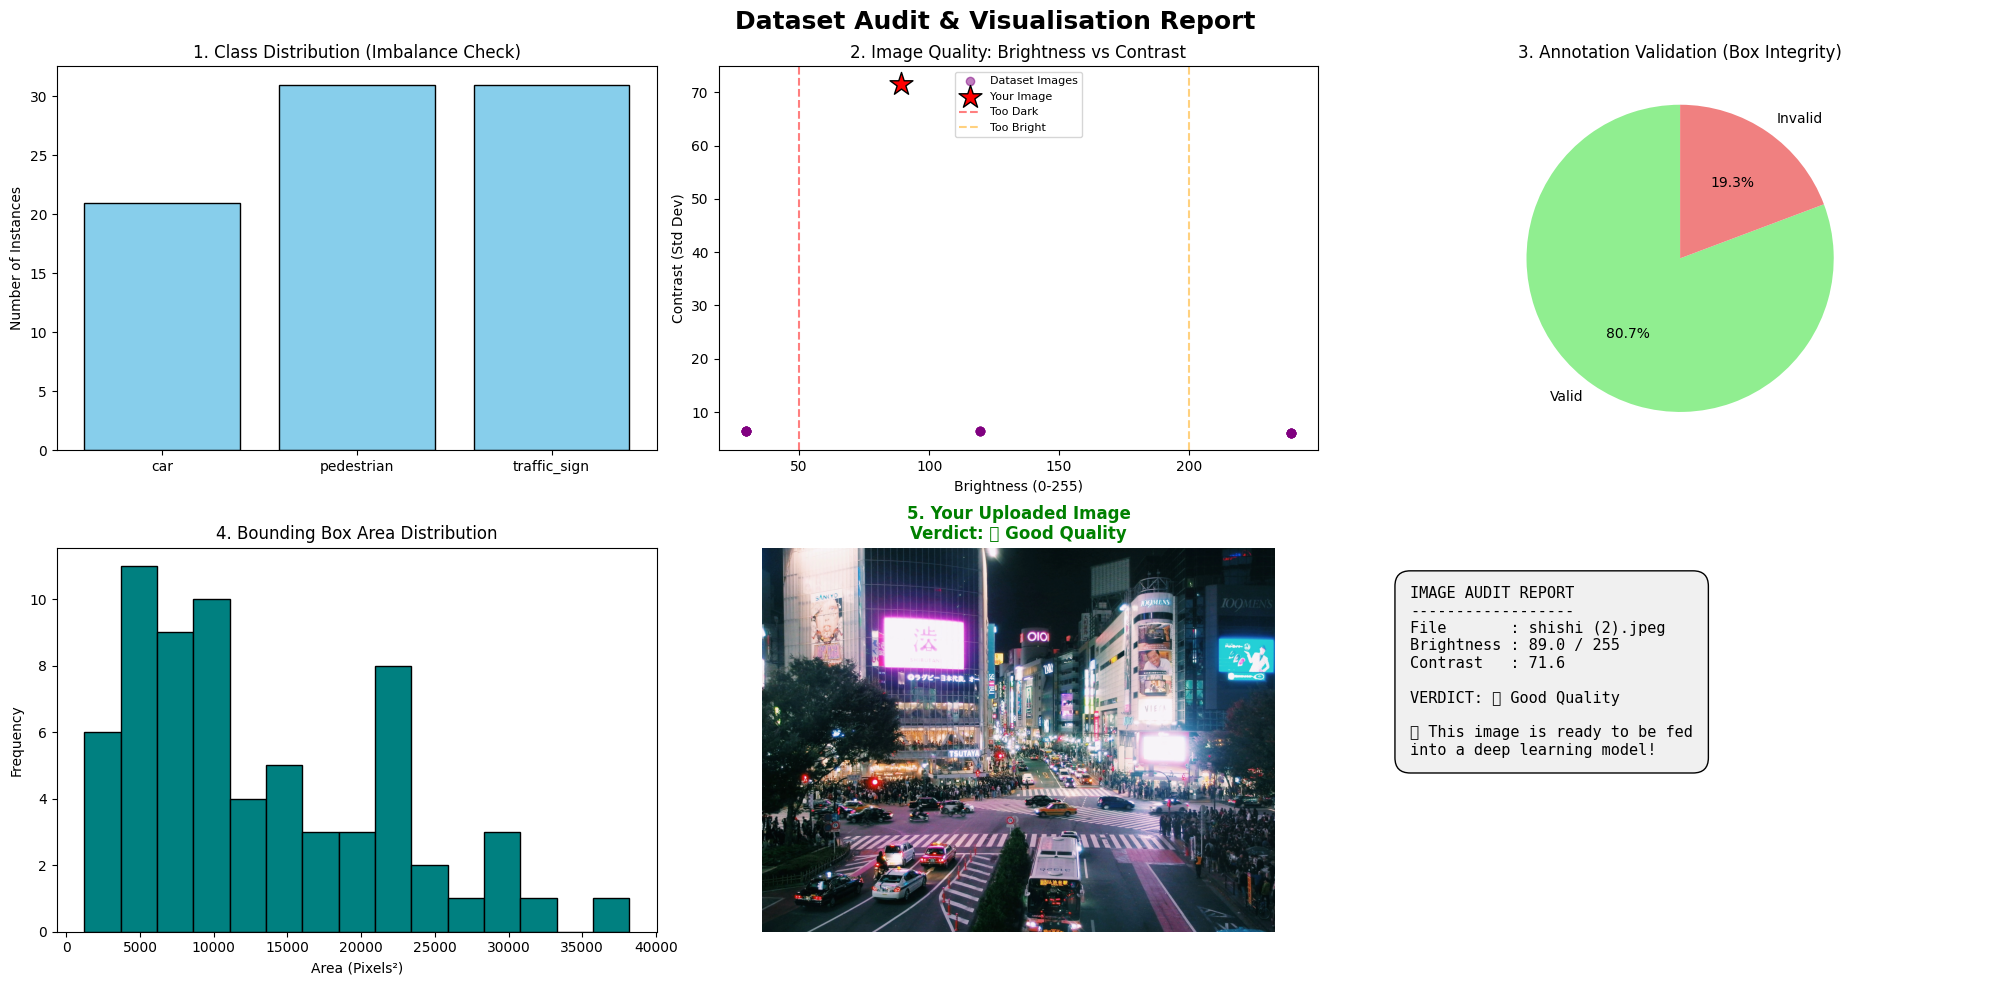

In [8]:
# ============================================================
# 📊 DATASET AUDIT & VISUALISATION
# Upload Image FIRST → Then Generate Graphs & Verdict
# ============================================================

import os, json, random, io
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from google.colab import files

# ============================================================
# 1. CREATE A MOCK DATASET (Simulating messy real-world data)
# ============================================================
print("📦 Generating a mock COCO dataset for auditing...")
os.makedirs("audit_data/images", exist_ok=True)

# Note: "pedestrian" is included here. It is a valid and important class!
classes = ["car", "pedestrian", "traffic_sign"]
class_to_id = {name: i+1 for i, name in enumerate(classes)}

coco_data = {
    "images": [],
    "annotations": [],
    "categories": [{"id": cid, "name": name} for name, cid in class_to_id.items()]
}

ann_id = 1
for img_id in range(1, 31):
    base_brightness = random.choice([30, 120, 240])
    img = np.ones((480, 640, 3), dtype=np.uint8) * base_brightness

    # Safe noise addition
    noise = np.random.randint(-20, 20, (480, 640, 3), dtype=np.int16)
    img_int = img.astype(np.int16) + noise
    img = np.clip(img_int, 0, 255).astype(np.uint8)

    img_path = f"audit_data/images/img_{img_id:03d}.jpg"
    Image.fromarray(img).save(img_path)

    coco_data["images"].append({"id": img_id, "file_name": f"img_{img_id:03d}.jpg", "width": 640, "height": 480})

    for _ in range(random.randint(1, 4)):
        cat = random.choice(list(class_to_id.values()))
        w = random.randint(20, 200)
        h = random.randint(20, 200)

        if img_id % 7 == 0:
            x, y = -10, -10          # Out of bounds
        elif img_id % 11 == 0:
            x, y = 620, 460          # Extends past edge
        else:
            x = random.randint(0, 640 - w)
            y = random.randint(0, 480 - h)

        coco_data["annotations"].append({
            "id": ann_id, "image_id": img_id, "category_id": cat,
            "bbox": [x, y, w, h], "area": w * h
        })
        ann_id += 1

with open("audit_data/annotations.json", "w") as f:
    json.dump(coco_data, f)
print("✅ Mock dataset created.")

# ============================================================
# 2. UPLOAD IMAGE FIRST
# ============================================================
print("\n" + "="*60)
print("🖼️ UPLOAD AN IMAGE FOR LIVE QUALITY AUDIT")
print("="*60)
uploaded = files.upload()

if not uploaded:
    print("❌ No image uploaded. Stopping.")
else:
    filename = list(uploaded.keys())[0]
    img_bytes = uploaded[filename]
    user_img = Image.open(io.BytesIO(img_bytes)).convert("RGB")
    user_img_np = np.array(user_img)

    # Audit user's image immediately
    gray = cv2.cvtColor(user_img_np, cv2.COLOR_RGB2GRAY)
    user_brightness = np.mean(gray)
    user_contrast   = np.std(gray)

    status, color = "✅ Good Quality", "green"
    if user_brightness < 50:
        status, color = "❌ Too Dark", "red"
    elif user_brightness > 200:
        status, color = "⚠️ Too Bright", "orange"
    elif user_contrast < 20:
        status, color = "⚠️ Low Contrast (Blurry)", "orange"

    print(f"✅ Image: {filename}")
    print(f"   • Brightness: {user_brightness:.2f} / 255")
    print(f"   • Contrast  : {user_contrast:.2f}")
    print(f"   • Verdict   : {status}")

    # ============================================================
    # 3. RUN DATASET AUDIT
    # ============================================================
    print("\n🔍 Running Dataset Audit...")

    img_metadata = {img["id"]: img for img in coco_data["images"]}
    cat_id_to_name = {c["id"]: c["name"] for c in coco_data["categories"]}

    class_counts = {name: 0 for name in class_to_id.keys()}
    brightness_scores, contrast_scores = [], []
    invalid_boxes, valid_boxes = [], []

    for ann in coco_data["annotations"]:
        class_counts[cat_id_to_name[ann["category_id"]]] += 1
        img_w = img_metadata[ann["image_id"]]["width"]
        img_h = img_metadata[ann["image_id"]]["height"]
        x, y, w, h = ann["bbox"]

        if x < 0 or y < 0 or (x + w) > img_w or (y + h) > img_h or w <= 0 or h <= 0:
            invalid_boxes.append(ann)
        else:
            valid_boxes.append(ann)

    for img in coco_data["images"]:
        img_path = f"audit_data/images/{img['file_name']}"
        loaded_img = cv2.imread(img_path)
        gray = cv2.cvtColor(loaded_img, cv2.COLOR_BGR2GRAY)
        brightness_scores.append(np.mean(gray))
        contrast_scores.append(np.std(gray))

    print(f"  • Total Annotations: {len(coco_data['annotations'])}")
    print(f"  • Valid Boxes      : {len(valid_boxes)}")
    print(f"  • Invalid Boxes    : {len(invalid_boxes)}")

    # ============================================================
    # 4. VISUALIZATION GRAPHS (Now includes your uploaded image)
    # ============================================================
    print("\n📊 Generating Audit Graphs...")

    fig, axes = plt.subplots(2, 3, figsize=(20, 10))
    fig.suptitle("Dataset Audit & Visualisation Report", fontsize=18, fontweight='bold')

    # Graph 1: Class Distribution
    axes[0, 0].bar(class_counts.keys(), class_counts.values(), color='skyblue', edgecolor='black')
    axes[0, 0].set_title("1. Class Distribution (Imbalance Check)")
    axes[0, 0].set_ylabel("Number of Instances")

    # Graph 2: Image Quality (with User Image plotted as a Star)
    axes[0, 1].scatter(brightness_scores, contrast_scores, color='purple', alpha=0.5, label='Dataset Images')
    axes[0, 1].scatter(user_brightness, user_contrast, color='red', marker='*', s=300, label='Your Image', edgecolor='black')
    axes[0, 1].set_title("2. Image Quality: Brightness vs Contrast")
    axes[0, 1].set_xlabel("Brightness (0-255)")
    axes[0, 1].set_ylabel("Contrast (Std Dev)")
    axes[0, 1].axvline(x=50,  color='red',    linestyle='--', alpha=0.5, label='Too Dark')
    axes[0, 1].axvline(x=200, color='orange', linestyle='--', alpha=0.5, label='Too Bright')
    axes[0, 1].legend(fontsize=8)

    # Graph 3: Annotation Validation
    axes[0, 2].pie([len(valid_boxes), len(invalid_boxes)],
                   labels=['Valid', 'Invalid'], autopct='%1.1f%%',
                   colors=['lightgreen', 'lightcoral'], startangle=90)
    axes[0, 2].set_title("3. Annotation Validation (Box Integrity)")

    # Graph 4: Bounding Box Area
    areas = [b["area"] for b in valid_boxes]
    axes[1, 0].hist(areas, bins=15, color='teal', edgecolor='black')
    axes[1, 0].set_title("4. Bounding Box Area Distribution")
    axes[1, 0].set_xlabel("Area (Pixels²)")
    axes[1, 0].set_ylabel("Frequency")

    # Graph 5: Your Uploaded Image Display
    axes[1, 1].imshow(user_img)
    axes[1, 1].set_title(f"5. Your Uploaded Image\nVerdict: {status}", color=color, fontweight='bold')
    axes[1, 1].axis('off')

    # Graph 6: Text Summary of the Uploaded Image
    axes[1, 2].axis('off')
    summary_text = (
        f"IMAGE AUDIT REPORT\n"
        f"------------------\n"
        f"File       : {filename}\n"
        f"Brightness : {user_brightness:.1f} / 255\n"
        f"Contrast   : {user_contrast:.1f}\n\n"
        f"VERDICT: {status}\n\n"
    )
    if "Dark" in status:
        summary_text += "How to fix: Apply histogram equalization\nor use a brighter photo."
    elif "Bright" in status:
        summary_text += "How to fix: Lower the exposure or use\n CLAHE to recover details."
    elif "Contrast" in status:
        summary_text += "How to fix: Sharpen the image or\n use a high-contrast photo."
    else:
        summary_text += "✅ This image is ready to be fed\ninto a deep learning model!"

    axes[1, 2].text(0.05, 0.9, summary_text, fontsize=11, va="top", family="monospace",
                    transform=axes[1, 2].transAxes,
                    bbox=dict(facecolor='#f0f0f0', edgecolor='black', boxstyle='round,pad=1'))

    plt.tight_layout()
    plt.show()